# Who Holds the Floor? Measuring meeting equity with TakeTheFloor

**305 EmpowHER Edition · October 2026 · Analytics Competition · Kaggle Challenge entry**
Author: Shermaine Yap Shi Min · App & code: https://github.com/ShermaineYap/305-EmpowHER-Edition-October-2026

Meetings are where leadership is visible — and where it is quietly lost. Three patterns are well documented:

1. **Airtime is uneven.** In mixed groups, women's share of speaking time often falls below their share of seats unless the group's rules change (Karpowitz, Mendelberg & Shaker, 2012).
2. **Interruptions are not evenly distributed.** Experimental work found speakers interrupted women more often than men (Hancock & Rubin, 2015).
3. **Ideas lose their author.** An idea raised by one person is repeated by another, who gets the credit. Women staffers in the Obama White House answered this with *amplification*: repeating a colleague's point **and naming her** (Washington Post, 2016).

This notebook does three things:

* defines **transparent, explainable metrics** for each pattern (airtime balance, interruptions vs. healthy overlap, idea-credit drift, a Hedge Index);
* **evaluates the detectors against hand-labelled meetings**, including a *healthy* control meeting so the method is tested for false alarms, not just hits;
* runs a **sensitivity analysis** on the key threshold, and closes with limitations and ethics.

> The demo meetings are **synthetic** (written for this project; all people fictional) with ground-truth labels in `data/demo_labels.json`. They are a test harness, not evidence about real populations. Section 7 shows how to run the same pipeline on real transcripts such as the AMI Meeting Corpus.

In [1]:
# Setup: works locally (repo checkout) and on Kaggle (installs from GitHub).
import os, sys, json, pathlib, subprocess, urllib.request
REPO = "https://github.com/ShermaineYap/305-EmpowHER-Edition-October-2026"
RAW = "https://raw.githubusercontent.com/ShermaineYap/305-EmpowHER-Edition-October-2026/main/data/"
here = pathlib.Path.cwd()
root = next((p for p in [here, here.parent] if (p / "takethefloor").exists()), None)
if root is None:  # Kaggle / Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{REPO}"], check=True)
    root = pathlib.Path("/kaggle/working") if pathlib.Path("/kaggle").exists() else here
    (root / "data").mkdir(exist_ok=True)
    for f in ["demo_product_launch.vtt", "demo_study_group.txt", "demo_balanced_standup.txt", "demo_labels.json"]:
        urllib.request.urlretrieve(RAW + f, root / "data" / f)
else:
    sys.path.insert(0, str(root))
DATA = root / "data"

import pandas as pd
import matplotlib.pyplot as plt
from takethefloor import parse_transcript, analyze
from takethefloor.parser import fmt_time
from takethefloor import credit as credit_mod

pd.set_option("display.max_colwidth", 90)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
print("Loaded data from", DATA)

Loaded data from /home/claude/305-empowher-edition-october-2026/data


## 1. Data: three labelled meetings

| Meeting | Format | What was planted |
|---|---|---|
| Product launch sync | Zoom WebVTT with real overlaps | 4 interruptions, 1 backchannel, 1 supportive "yes, and…", 1 idea credited to the wrong person |
| University project group | `[hh:mm:ss] Name:` | 1 interruption, 1 credit drift, 1 *credited build* (healthy) |
| Daily stand-up (control) | plain `Name:` lines, no timestamps | no interruptions, 1 credited build |

In [2]:
MEETINGS = {
    "Product launch": "demo_product_launch.vtt",
    "Project group": "demo_study_group.txt",
    "Stand-up (control)": "demo_balanced_standup.txt",
}
LABELS = json.loads((DATA / "demo_labels.json").read_text())
results = {}
for name, f in MEETINGS.items():
    text = (DATA / f).read_text()
    turns = parse_transcript(text)
    results[name] = analyze(turns, timestamps_real="standup" not in f)
pd.DataFrame([
    {"Meeting": n, "Turns": len(r["turns"]), "People": len(r["speakers"]), "Length": fmt_time(r["duration"]),
     "Airtime balance": r["equity_index"], "Interruptions": r["counts"]["interruptions"],
     "Credit drift": r["counts"]["credit_drift"], "Floor Health": r["floor_health"]}
    for n, r in results.items()
])

,Meeting,Turns,People,Length,Airtime balance,Interruptions,Credit drift,Floor Health
0,Product launch,32,5,04:10,63.2,4,1,38
1,Project group,18,4,01:54,66.7,1,1,64
2,Stand-up (control),10,4,00:52,71.8,0,0,86


## 2. Airtime — who held the floor

**Airtime balance** = 100 × (1 − normalised Gini coefficient of talk-time share). 100 means everyone spoke equally; it falls as one voice dominates. Talk time comes from cue timestamps where they exist and from word counts (≈150 wpm) where they don't.

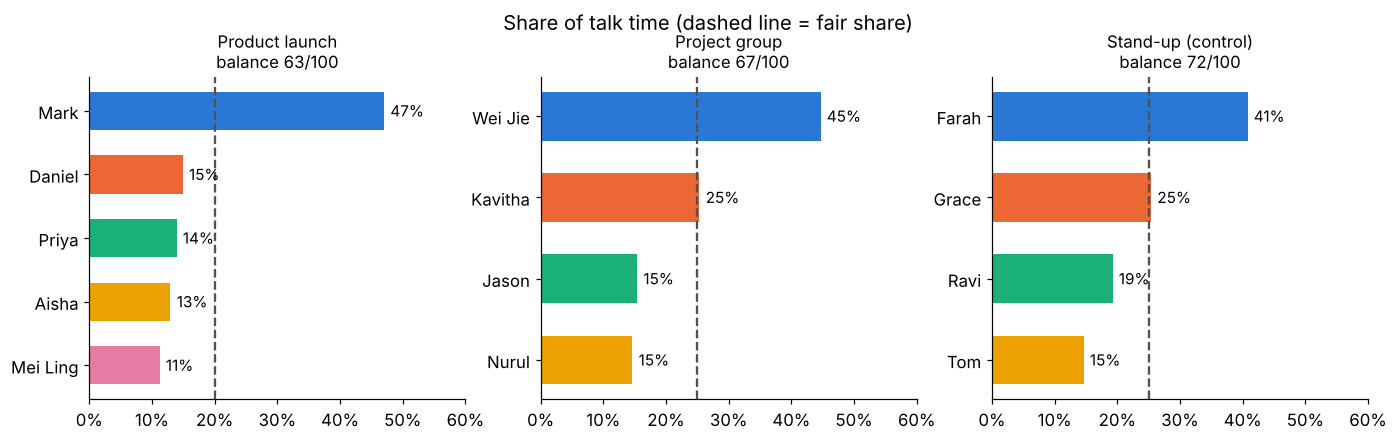

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, (name, r) in zip(axes, results.items()):
    sp = r["speakers"]
    shares = [r["stats"][s]["talk_share"] for s in sp]
    ax.barh(sp, shares, color=[SERIES[i % 8] for i in range(len(sp))], height=0.6)
    ax.axvline(1 / len(sp), color="#52514e", ls="--", lw=1.5)
    for y, v in enumerate(shares):
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=10)
    ax.set_xlim(0, 0.6); ax.invert_yaxis(); ax.set_title(f"{name}\nbalance {r['equity_index']:.0f}/100", fontsize=11)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Share of talk time (dashed line = fair share)", y=1.04)
plt.show()

The product-launch facilitator holds almost half the airtime — more than twice a fair share — while the two people with the strongest data and pricing ideas sit at the bottom. In the control stand-up the facilitator also speaks most (calling on each person is facilitation work), but nobody is cut off.

## 3. Interruptions vs. healthy overlap

A speaker change becomes a **candidate** when the previous speaker was cut off mid-sentence (dash, ellipsis, missing end punctuation) or the timestamps overlap. Candidates are then classified, because conversation research distinguishes:

* **backchannels** — "mm-hmm", "yeah": listening signals that don't take the floor;
* **supportive overlaps** — "Yes, and…": cooperative, building on the point;
* **interruptions** — taking the floor away or redirecting before the speaker finished.

Rules handle this offline; in the app, **Gemma re-labels each candidate** with surrounding context.

In [4]:
r = results["Product launch"]
pd.DataFrame([{"Time": fmt_time(e["time"]), "Who spoke": e["interrupter"], "Over": e["interrupted"],
               "Signal": e["signal"], "Label": e["label"], "Opening words": e["taking_text"][:70]} for e in r["interruptions"]])

,Time,Who spoke,Over,Signal,Label,Opening words
0,01:14,Mark,Mei Ling,cut-off,interruption,"Yeah, the beta was tiny though, I wouldn't read too much into it. Dani"
1,01:40,Mark,Aisha,cut-off,interruption,Let's not overcomplicate it. Multiple tiers means more support tickets
2,01:59,Daniel,Priya,overlap,backchannel,Yeah.
3,02:07,Aisha,Priya,overlap,supportive,"Yes, and if we move the payment step after the first study session, th"
4,02:57,Daniel,Mei Ling,cut-off,interruption,"Paid social is just faster though, referrals take forever to ramp up."
5,03:55,Mark,Aisha,overlap,interruption,"Sure, sure. Anyway, Mei Ling, can you model what half price does to re"


## 4. Idea credit drift

An idea is an *echo* when a later turn by a different person has cosine similarity ≥ 0.28 over content words with an earlier proposal, sharing ≥ 3 key terms, at least 20 s later. We then look at what the room did next: praise or attribution to the echoer while the originator was never acknowledged = **credit drift**; naming the originator = **credited build**.

In [5]:
rows = []
for name, r in results.items():
    for c in r["credit_events"]:
        rows.append({"Meeting": name, "Outcome": c["outcome"], "Idea": c["summary"], "Raised by": c["originator"],
                     "at": fmt_time(c["original_time"]), "Repeated by": c["echoed_by"], "at ": fmt_time(c["echo_time"]),
                     "Credited to": c["credited_to"], "Similarity": c["similarity"]})
pd.DataFrame(rows)

,Meeting,Outcome,Idea,Raised by,at,Repeated by,at,Credited to,Similarity
0,Product launch,credit_drift,Launch a student tier at half the price,Aisha,01:29,Mark,03:29,Mark,0.73
1,Project group,credit_drift,Something on public transport,Nurul,00:11,Wei Jie,01:12,Wei Jie,0.49
2,Project group,credited_build,Look at how food inflation changed by state,Jason,00:22,Kavitha,00:59,Jason,0.16
3,Stand-up (control),credited_build,Switch the grey text to the darker token this sprint,Grace,00:12,Ravi,00:26,Grace,0.19


## 5. Evaluation against ground truth

Every planted event is scored. The control meeting matters most: a detector that flags everything would look great on recall and fail here.

In [6]:
def prf(got, want):
    got, want = list(got), list(want)
    tp = sum(min(got.count(x), want.count(x)) for x in set(want))
    p = tp / len(got) if got else 1.0
    r_ = tp / len(want) if want else 1.0
    return tp, len(got), len(want), p, r_

rows = []
for name, f in MEETINGS.items():
    r, lab = results[name], LABELS[f]
    gi = [(e["interrupter"], e["interrupted"]) for e in r["interruptions"] if e["label"] == "interruption"]
    wi = [(x["interrupter"], x["interrupted"]) for x in lab["interruptions"]]
    gc = [(c["outcome"], c["originator"], c["echoed_by"]) for c in r["credit_events"]]
    wc = [(x["outcome"], x["originator"], x["echoed_by"]) for x in lab["credit"]]
    for task, g, w in [("Interruptions", gi, wi), ("Idea credit", gc, wc)]:
        tp, ng, nw, p, rc = prf(g, w)
        rows.append({"Meeting": name, "Task": task, "Labelled": nw, "Detected": ng, "Correct": tp, "Precision": p, "Recall": rc})
ev = pd.DataFrame(rows)
tot = ev.groupby("Task")[["Labelled", "Detected", "Correct"]].sum()
tot["Precision"] = tot["Correct"] / tot["Detected"]; tot["Recall"] = tot["Correct"] / tot["Labelled"]
display(ev.style.format({"Precision": "{:.0%}", "Recall": "{:.0%}"}))
display(tot.style.format({"Precision": "{:.0%}", "Recall": "{:.0%}"}))

,Meeting,Task,Labelled,Detected,Correct,Precision,Recall
0,Product launch,Interruptions,4,4,4,100%,100%
1,Product launch,Idea credit,1,1,1,100%,100%
2,Project group,Interruptions,1,1,1,100%,100%
3,Project group,Idea credit,2,2,2,100%,100%
4,Stand-up (control),Interruptions,0,0,0,100%,100%
5,Stand-up (control),Idea credit,1,1,1,100%,100%


,Labelled,Detected,Correct,Precision,Recall
Task,,,,,
Idea credit,4,4,4,100%,100%
Interruptions,5,5,5,100%,100%


**Read this honestly:** perfect scores on three hand-built meetings show the detectors do what they were designed to do — including staying quiet on the healthy stand-up and correctly *not* counting the backchannel and the "yes, and…" overlap. They are **not** a claim of real-world accuracy; the synthetic meetings were written by the same person who wrote the rules. Section 6 probes how fragile the result is.

## 6. Sensitivity: how fragile is idea-credit detection?

Sweep the similarity threshold and count, across all three meetings, correct detections vs. false alarms.

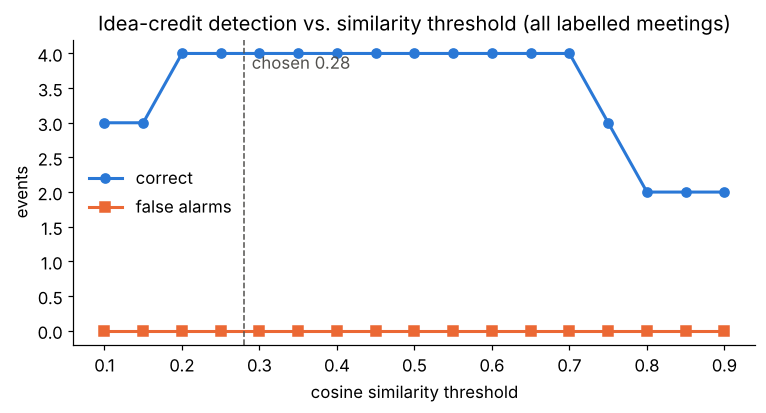

,threshold,correct,false alarms
0,0.10,3,0
1,0.15,3,0
2,0.20,4,0
3,0.25,4,0
4,0.30,4,0
5,0.35,4,0
6,0.40,4,0
7,0.45,4,0
8,0.50,4,0
9,0.55,4,0


In [7]:
import numpy as np
want_all = {(f, x["outcome"], x["originator"], x["echoed_by"]) for f in LABELS for x in LABELS[f]["credit"]}
rows = []
for th in np.round(np.arange(0.10, 0.95, 0.05), 2):
    got = set()
    for name, f in MEETINGS.items():
        for c in credit_mod.detect(results[name]["turns"], sim_threshold=float(th)):
            got.add((f, c["outcome"], c["originator"], c["echoed_by"]))
    rows.append({"threshold": th, "correct": len(got & want_all), "false alarms": len(got - want_all)})
sens = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(sens["threshold"], sens["correct"], marker="o", lw=2, color=SERIES[0], label="correct")
ax.plot(sens["threshold"], sens["false alarms"], marker="s", lw=2, color=SERIES[1], label="false alarms")
ax.axvline(0.28, color="#52514e", ls="--", lw=1); ax.text(0.29, ax.get_ylim()[1] * 0.9, "chosen 0.28", color="#52514e")
ax.set_xlabel("cosine similarity threshold"); ax.set_ylabel("events"); ax.legend(frameon=False)
ax.set_title("Idea-credit detection vs. similarity threshold (all labelled meetings)")
plt.show()
sens

Explicitly credited builds ("Building on Grace's audit…") are found by name and are stable at every threshold. Credit drift shows two failure modes at the extremes: **too low** (≤ 0.15) and the earliest loosely-related turn — here the facilitator's own opening remarks — is picked as the "origin", so the true originator loses the credit a second time; **too high** (≥ 0.75) and a genuine paraphrase is missed. Between 0.20 and 0.70 the result is a flat plateau with zero false alarms, and the chosen 0.28 sits near its low end so that real-world paraphrases (which overlap less than these scripts) still register. In the app, Gemma adds semantic judgement on top (titles, recap, coaching), while these transparent rules keep every flag explainable with the exact quotes.

## 7. Floor Health — one number for a facilitator

`Floor Health = 0.6 × airtime balance + 40 − 7 × interruptions − 12 × credit drift + 3 × credited builds` (clamped 0–100). The weights are a design choice, published so teams can disagree with them.

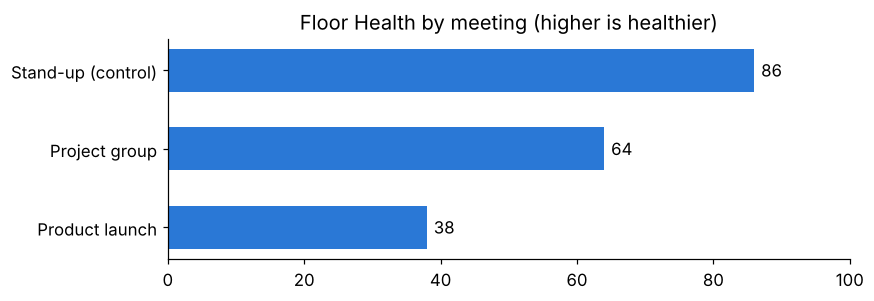

In [8]:
fh = pd.Series({n: r["floor_health"] for n, r in results.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.barh(fh.index, fh.values, color=SERIES[0], height=0.55)
for y, v in enumerate(fh.values): ax.text(v + 1, y, f"{v:.0f}", va="center")
ax.set_xlim(0, 100); ax.set_title("Floor Health by meeting (higher is healthier)")
plt.show()

## 8. Run it on real meetings

```python
from takethefloor import parse_transcript, analyze
r = analyze(parse_transcript(open("my_meeting.vtt").read()))
```

Supported inputs: WebVTT from Zoom/Teams/Meet, `[hh:mm:ss] Name: text`, `Name (hh:mm:ss): text`, Otter-style headers and plain `Name: text`. For the **AMI Meeting Corpus** (CC BY 4.0), convert the word-level annotations to `[start] Speaker: utterance` lines per segment and pass them in; AMI's speaker IDs and roles let you compare airtime by role. Set `GEMINI_API_KEY` to have Gemma re-label interruptions and write recaps and coaching.

## 9. Limitations & ethics

* **Synthetic validation only.** Real transcripts are noisier (ASR errors, missing punctuation, cross-talk merged into one cue).
* **Culture and context.** Overlap norms differ across cultures and teams; high-involvement conversational styles overlap a lot without hostility. That's why backchannels and supportive overlaps are separated, and why every flag shows the evidence.
* **Not a performance score.** TakeTheFloor describes one meeting. It should start conversations and change meeting *structure* (round-robins, naming idea owners), not rank or discipline people. Coaching notes are private to the individual; names can be anonymised before sharing.
* **Privacy.** Rules-only mode and local Gemma via Ollama keep transcripts on-device.

## References
* Karpowitz, C. F., Mendelberg, T., & Shaker, L. (2012). Gender Inequality in Deliberative Participation. *American Political Science Review*, 106(3).
* Hancock, A. B., & Rubin, B. A. (2015). Influence of Communication Partner's Gender on Language. *Journal of Language and Social Psychology*, 34(1).
* Eilperin, J. (2016, Sept 13). White House women want to be in the room where it happens. *The Washington Post*. (origin of "amplification")
* Carletta, J. et al. (2005). The AMI Meeting Corpus. *MLMI 2005*.